# RQ1 prototype

RQ1 counts tools named in skill text. This notebook keeps a Relex hit when a `tool` span is tied to an `organization` by `from_organization`. The organization is the publisher named beside the tool in the text. It is not the skill's hosting repository. `curl` and bare `github` appear only when the model makes them the tool head of that relation.

Run this notebook from `scripts/` with the project virtualenv, the same way as `test.ipynb`. The first run downloads `knowledgator/gliner-relex-large-v0.5`.


In [1]:
import re

import polars as pl
import seaborn_polars as snl
from gliner import GLiNER
from IPython.display import display

from tool_extraction import artifacts

SEED = 7
SAMPLE_N = 12
MAX_LENGTH = 384
MAX_WORDS_CONTEXT = 5
HIT_THRESHOLD = 0.6
HIT_RELATION_THRESHOLD = 0.6
STARSHIP_REPO = "jyasuu/cheat-sheet"
STARSHIP_PATH = "skills/starship/SKILL.md"
HIT_LABELS = ["tool", "organization"]
HIT_RELATION_LABELS = ["from_organization"]

RELATION_SCHEMA = {
    "file_sha": pl.String,
    "snippet": pl.List(pl.String),
    "entity": pl.String,
    "label": pl.String,
    "relation": pl.String,
    "related": pl.String,
    "related_label": pl.String,
    "score": pl.Float64,
    "repo_full_name": pl.String,
}


/home/nichmorgan/Projects/nau/msr-data-challenge-2027/scripts/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
population = artifacts.filter(
    (pl.col("dedup_primary") == 1)
    & (pl.col("frontmatter_valid") == 1)
    & pl.col("content").is_not_null()
    & (pl.col("filename").str.to_lowercase() == "skill.md")
    & pl.col("location_class").is_in(["canonical", "skills-dir"])
    & pl.col("body_chars").is_between(80, 1500)
).select("file_sha", "repo_full_name", "path", "content")


In [3]:
model = GLiNER.from_pretrained("knowledgator/gliner-relex-large-v0.5")
print(next(model.parameters()).device)


/home/nichmorgan/Projects/nau/msr-data-challenge-2027/scripts/.venv/lib/python3.13/site-packages/huggingface_hub/utils/_validators.py:190: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

cpu


In [4]:
def get_snippet(text: str, entity: str) -> list[str]:
    if not text or not entity:
        return []
    pattern = re.compile(rf"(?<!\w){re.escape(entity)}(?!\w)")
    snippets = []
    for match in pattern.finditer(text):
        before = text[: match.start()].split()
        after = text[match.end() :].split()
        highlighted = f"[{match.group()}]"
        snippet = " ".join(before[-MAX_WORDS_CONTEXT:] + [highlighted] + after[:MAX_WORDS_CONTEXT])
        if len(before) > MAX_WORDS_CONTEXT:
            snippet = "..." + snippet
        if len(after) > MAX_WORDS_CONTEXT:
            snippet = snippet + "..."
        snippets.append(snippet)
    return snippets


def span_label(span: dict) -> str:
    if "label" in span:
        return span["label"]
    return span["type"]


def extract(skills: pl.DataFrame) -> pl.DataFrame:
    texts = [(text or "")[:MAX_LENGTH] for text in skills["content"].to_list()]
    _, relations = model.inference(
        texts,
        labels=HIT_LABELS,
        relations=HIT_RELATION_LABELS,
        threshold=HIT_THRESHOLD,
        relation_threshold=HIT_RELATION_THRESHOLD,
        return_relations=True,
        flat_ner=True,
    )
    rows = []
    for row, text, linked in zip(skills.iter_rows(named=True), texts, relations, strict=True):
        for relation in linked:
            head = relation["head"]
            tail = relation["tail"]
            rows.append(
                {
                    "file_sha": row["file_sha"],
                    "snippet": get_snippet(text, head["text"]),
                    "entity": head["text"],
                    "label": span_label(head),
                    "relation": relation["relation"],
                    "related": tail["text"],
                    "related_label": span_label(tail),
                    "score": float(relation["score"]),
                    "repo_full_name": row["repo_full_name"],
                }
            )
    hits = pl.DataFrame(rows, schema=RELATION_SCHEMA)
    return hits.with_columns(
        pl.when(pl.col("snippet").list.len() == 0)
        .then(pl.lit(["(no match)"]))
        .otherwise(pl.col("snippet"))
        .alias("snippet")
    )


def tool_counts(relations: pl.DataFrame) -> pl.DataFrame:
    schema = {"tool": pl.String, "label": pl.String, "skills": pl.UInt32}
    tools = relations.filter(pl.col("label") == "tool")
    if tools.is_empty():
        return pl.DataFrame(schema=schema)
    folded = tools.with_columns(pl.col("entity").str.to_lowercase().alias("key"))
    return (
        folded.group_by("key")
        .agg(
            pl.col("file_sha").n_unique().alias("skills"),
            pl.col("label").mode().first().alias("label"),
            pl.col("entity").mode().first().alias("tool"),
        )
        .sort("skills", descending=True)
        .select("tool", "label", "skills")
    )


## Worked skill

`jyasuu/cheat-sheet` `skills/starship/SKILL.md` installs Starship with `curl` and links the docs to a GitHub project. The kept name is a tool head of `from_organization`. `jyasuu` is not kept for being the skill owner. `curl` and bare `github` are absent unless the model makes them that tool head.


In [5]:
worked = population.filter(
    (pl.col("repo_full_name") == STARSHIP_REPO) & (pl.col("path") == STARSHIP_PATH)
).collect()
worked_relations = extract(worked)
display(worked_relations)
worked_relations.filter(pl.col("label") == "tool")


file_sha,snippet,entity,label,relation,related,related_label,score,repo_full_name
str,list[str],str,str,str,str,str,f64,str


file_sha,snippet,entity,label,relation,related,related_label,score,repo_full_name
str,list[str],str,str,str,str,str,f64,str


## Frequency sample

Twelve other short skills, drawn with a fixed seed. Keys are collected first, then only those twelve skill texts.


In [6]:
sample_keys = (
    population.filter(
        ~((pl.col("repo_full_name") == STARSHIP_REPO) & (pl.col("path") == STARSHIP_PATH))
    )
    .select("file_sha", "repo_full_name", "path")
    .collect()
    .sample(n=SAMPLE_N, seed=SEED)
)
sample = population.join(
    sample_keys.lazy(),
    on=["file_sha", "repo_full_name", "path"],
    how="semi",
).collect()
sample.select("repo_full_name", "path")


repo_full_name,path
str,str
"""sisodiabhumca/agent-skills""","""skills/marketing-attribution-s…"
"""KT-lcz/opencode-sdd-kit""","""packages/cli/opencode/skills/s…"
"""DYAI2025/Plumbline""","""config/claude/skills/root-caus…"
"""Sri-Krishna-V/companies""","""product-compass-consulting/ski…"
"""javimosch/supercli""","""plugins/gh-sql/skills/quicksta…"
…,…
"""joshuadavidthomas/django-langu…",""".agents/skills/djls-salsa/SKIL…"
"""kk0ga/employee-time-attendance""",""".github/skills/static-hosting-…"
"""AngelQuinteroDev/BlockWeb""",""".github/skills/desktop-ui/SKIL…"


In [7]:
sample_relations = extract(sample)
display(sample_relations)
sample_relations.filter(pl.col("label") == "tool")


file_sha,snippet,entity,label,relation,related,related_label,score,repo_full_name
str,list[str],str,str,str,str,str,f64,str
"""327fe4502fe3d25ad78c6e3fa79660…","[""--- name: [marketing-attribution-sanity-checker] description: Vendor-neutral skill to audit...""]","""marketing-attribution-sanity-c…","""tool""","""from_organization""","""Vendor-neutral""","""organization""",0.703822,"""sisodiabhumca/agent-skills"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""--- name: [sdd-workflow] description: Follow the SDD workflow...""]","""sdd-workflow""","""tool""","""from_organization""","""SDD""","""organization""",0.868246,"""KT-lcz/opencode-sdd-kit"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""...SDD phases - Prefer ` [sdd_bootstrap] `, `sdd_schedule`, and `sdd_status` over...""]","""sdd_bootstrap""","""tool""","""from_organization""","""SDD""","""organization""",0.853846,"""KT-lcz/opencode-sdd-kit"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""...phases - Prefer `sdd_bootstrap`, ` [sdd_schedule] `, and `sdd_status` over ad-hoc...""]","""sdd_schedule""","""tool""","""from_organization""","""SDD""","""organization""",0.880042,"""KT-lcz/opencode-sdd-kit"""
"""d51538b2a88483a9b575b9576db904…","[""--- name: [identify-assumptions-new] description: ""Identify risky assumptions for..."", ""...github-file repo: phuryn/pm-skills path: pm-product-discovery/skills/ [identify-assumptions-new] /SKILL.md commit: 36ccefdc6c2e00d7c0c12cb0a52bf93e8ec50da4 attribu""]","""identify-assumptions-new""","""tool""","""from_organization""","""phuryn""","""organization""",0.935993,"""Sri-Krishna-V/companies"""
…,…,…,…,…,…,…,…,…
"""cda962d1336ce3ff343e225d729019…","[""--- name: [static-hosting-ci-cd] description: 'CSR前提のフロントを静的ホスティングで配信する。GitHub Pages と Cloudflare...""]","""static-hosting-ci-cd""","""tool""","""from_organization""","""Cloudflare""","""organization""",0.832113,"""kk0ga/employee-time-attendance"""
"""cda962d1336ce3ff343e225d729019…","[""--- name: [static-hosting-ci-cd] description: 'CSR前提のフロントを静的ホスティングで配信する。GitHub Pages と Cloudflare...""]","""static-hosting-ci-cd""","""tool""","""from_organization""","""MIT""","""organization""",0.835778,"""kk0ga/employee-time-attendance"""
"""802fb16aeae3b06012ae37e460d778…","[""--- name: [desktop-ui] description: ""Use when designing desktop...""]","""desktop-ui""","""tool""","""from_organization""","""Windows""","""organization""",0.843434,"""AngelQuinteroDev/BlockWeb"""


file_sha,snippet,entity,label,relation,related,related_label,score,repo_full_name
str,list[str],str,str,str,str,str,f64,str
"""327fe4502fe3d25ad78c6e3fa79660…","[""--- name: [marketing-attribution-sanity-checker] description: Vendor-neutral skill to audit...""]","""marketing-attribution-sanity-c…","""tool""","""from_organization""","""Vendor-neutral""","""organization""",0.703822,"""sisodiabhumca/agent-skills"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""--- name: [sdd-workflow] description: Follow the SDD workflow...""]","""sdd-workflow""","""tool""","""from_organization""","""SDD""","""organization""",0.868246,"""KT-lcz/opencode-sdd-kit"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""...SDD phases - Prefer ` [sdd_bootstrap] `, `sdd_schedule`, and `sdd_status` over...""]","""sdd_bootstrap""","""tool""","""from_organization""","""SDD""","""organization""",0.853846,"""KT-lcz/opencode-sdd-kit"""
"""8b18fb6d746b86ba4b7f6f61b2c439…","[""...phases - Prefer `sdd_bootstrap`, ` [sdd_schedule] `, and `sdd_status` over ad-hoc...""]","""sdd_schedule""","""tool""","""from_organization""","""SDD""","""organization""",0.880042,"""KT-lcz/opencode-sdd-kit"""
"""d51538b2a88483a9b575b9576db904…","[""--- name: [identify-assumptions-new] description: ""Identify risky assumptions for..."", ""...github-file repo: phuryn/pm-skills path: pm-product-discovery/skills/ [identify-assumptions-new] /SKILL.md commit: 36ccefdc6c2e00d7c0c12cb0a52bf93e8ec50da4 attribu""]","""identify-assumptions-new""","""tool""","""from_organization""","""phuryn""","""organization""",0.935993,"""Sri-Krishna-V/companies"""
…,…,…,…,…,…,…,…,…
"""cda962d1336ce3ff343e225d729019…","[""--- name: [static-hosting-ci-cd] description: 'CSR前提のフロントを静的ホスティングで配信する。GitHub Pages と Cloudflare...""]","""static-hosting-ci-cd""","""tool""","""from_organization""","""Cloudflare""","""organization""",0.832113,"""kk0ga/employee-time-attendance"""
"""cda962d1336ce3ff343e225d729019…","[""--- name: [static-hosting-ci-cd] description: 'CSR前提のフロントを静的ホスティングで配信する。GitHub Pages と Cloudflare...""]","""static-hosting-ci-cd""","""tool""","""from_organization""","""MIT""","""organization""",0.835778,"""kk0ga/employee-time-attendance"""
"""802fb16aeae3b06012ae37e460d778…","[""--- name: [desktop-ui] description: ""Use when designing desktop...""]","""desktop-ui""","""tool""","""from_organization""","""Windows""","""organization""",0.843434,"""AngelQuinteroDev/BlockWeb"""


## Counts

Tool heads fold without case, and the name on the bar is the most common original spelling. `skills` is the number of distinct skill files.


tool,label,skills
str,str,u32
"""SKILL.md""","""tool""",1
"""djls-salsa""","""tool""",1
"""AGENTS.md""","""tool""",1
"""desktop-ui""","""tool""",1
"""aifi-release-check""","""tool""",1
…,…,…
"""static-hosting-ci-cd""","""tool""",1
"""sql""","""tool""",1
"""gh-sql""","""tool""",1


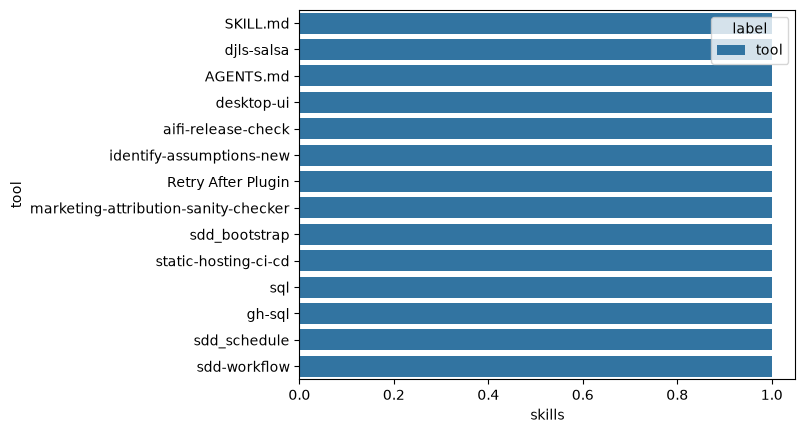

In [8]:
counts = tool_counts(sample_relations)
top = counts.head(15)
display(top)
if top.is_empty():
    print("No tool heads were linked to an organization.")
else:
    snl.barplot(top, y="tool", x="skills", hue="label", order=top["tool"].to_list())
